saved the figure lab
saved the figure body


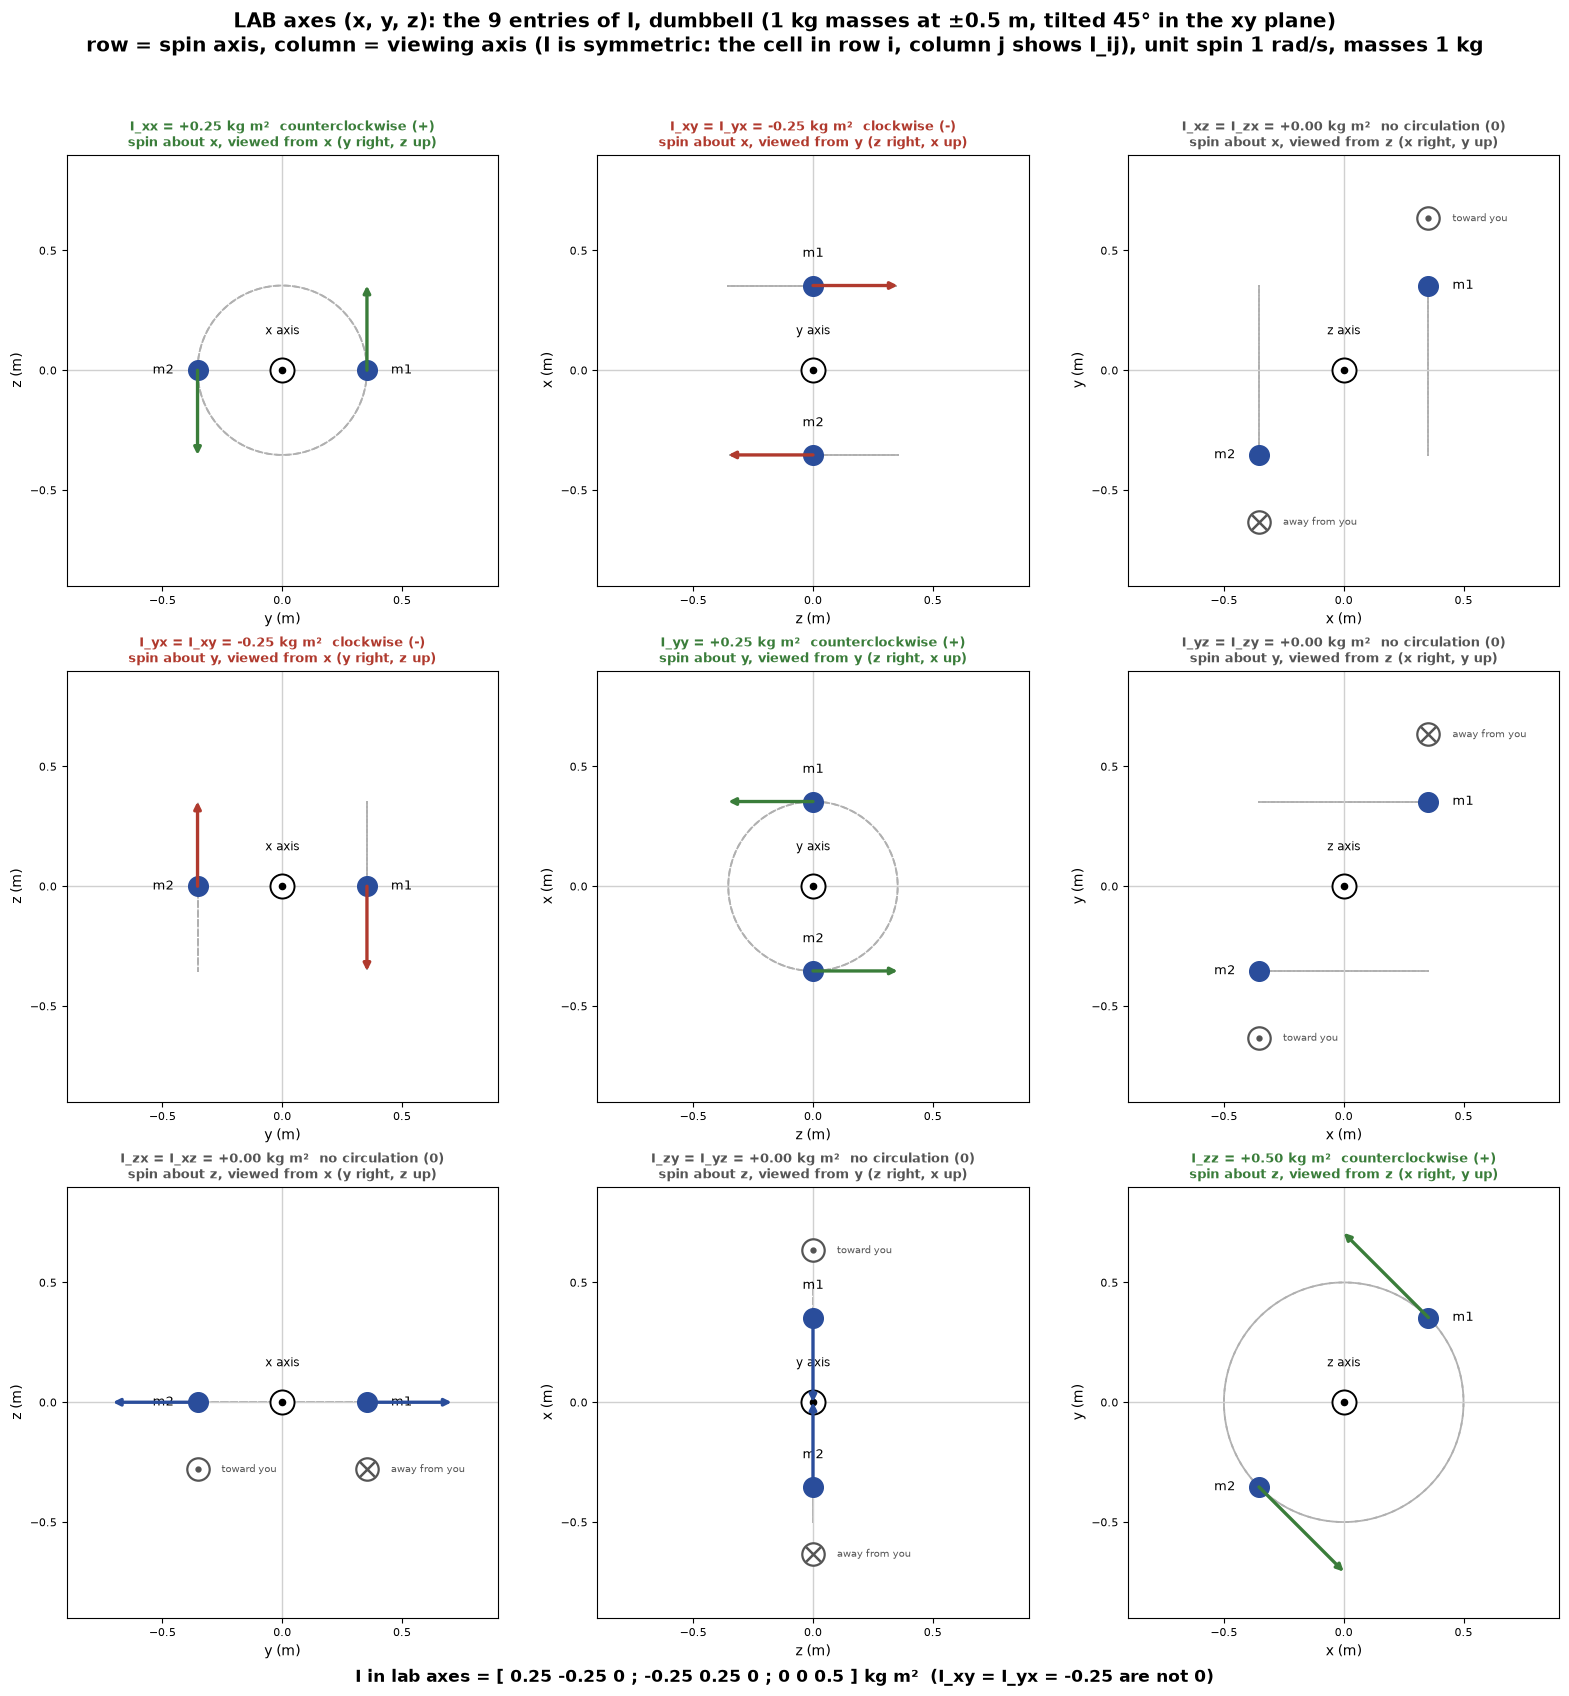

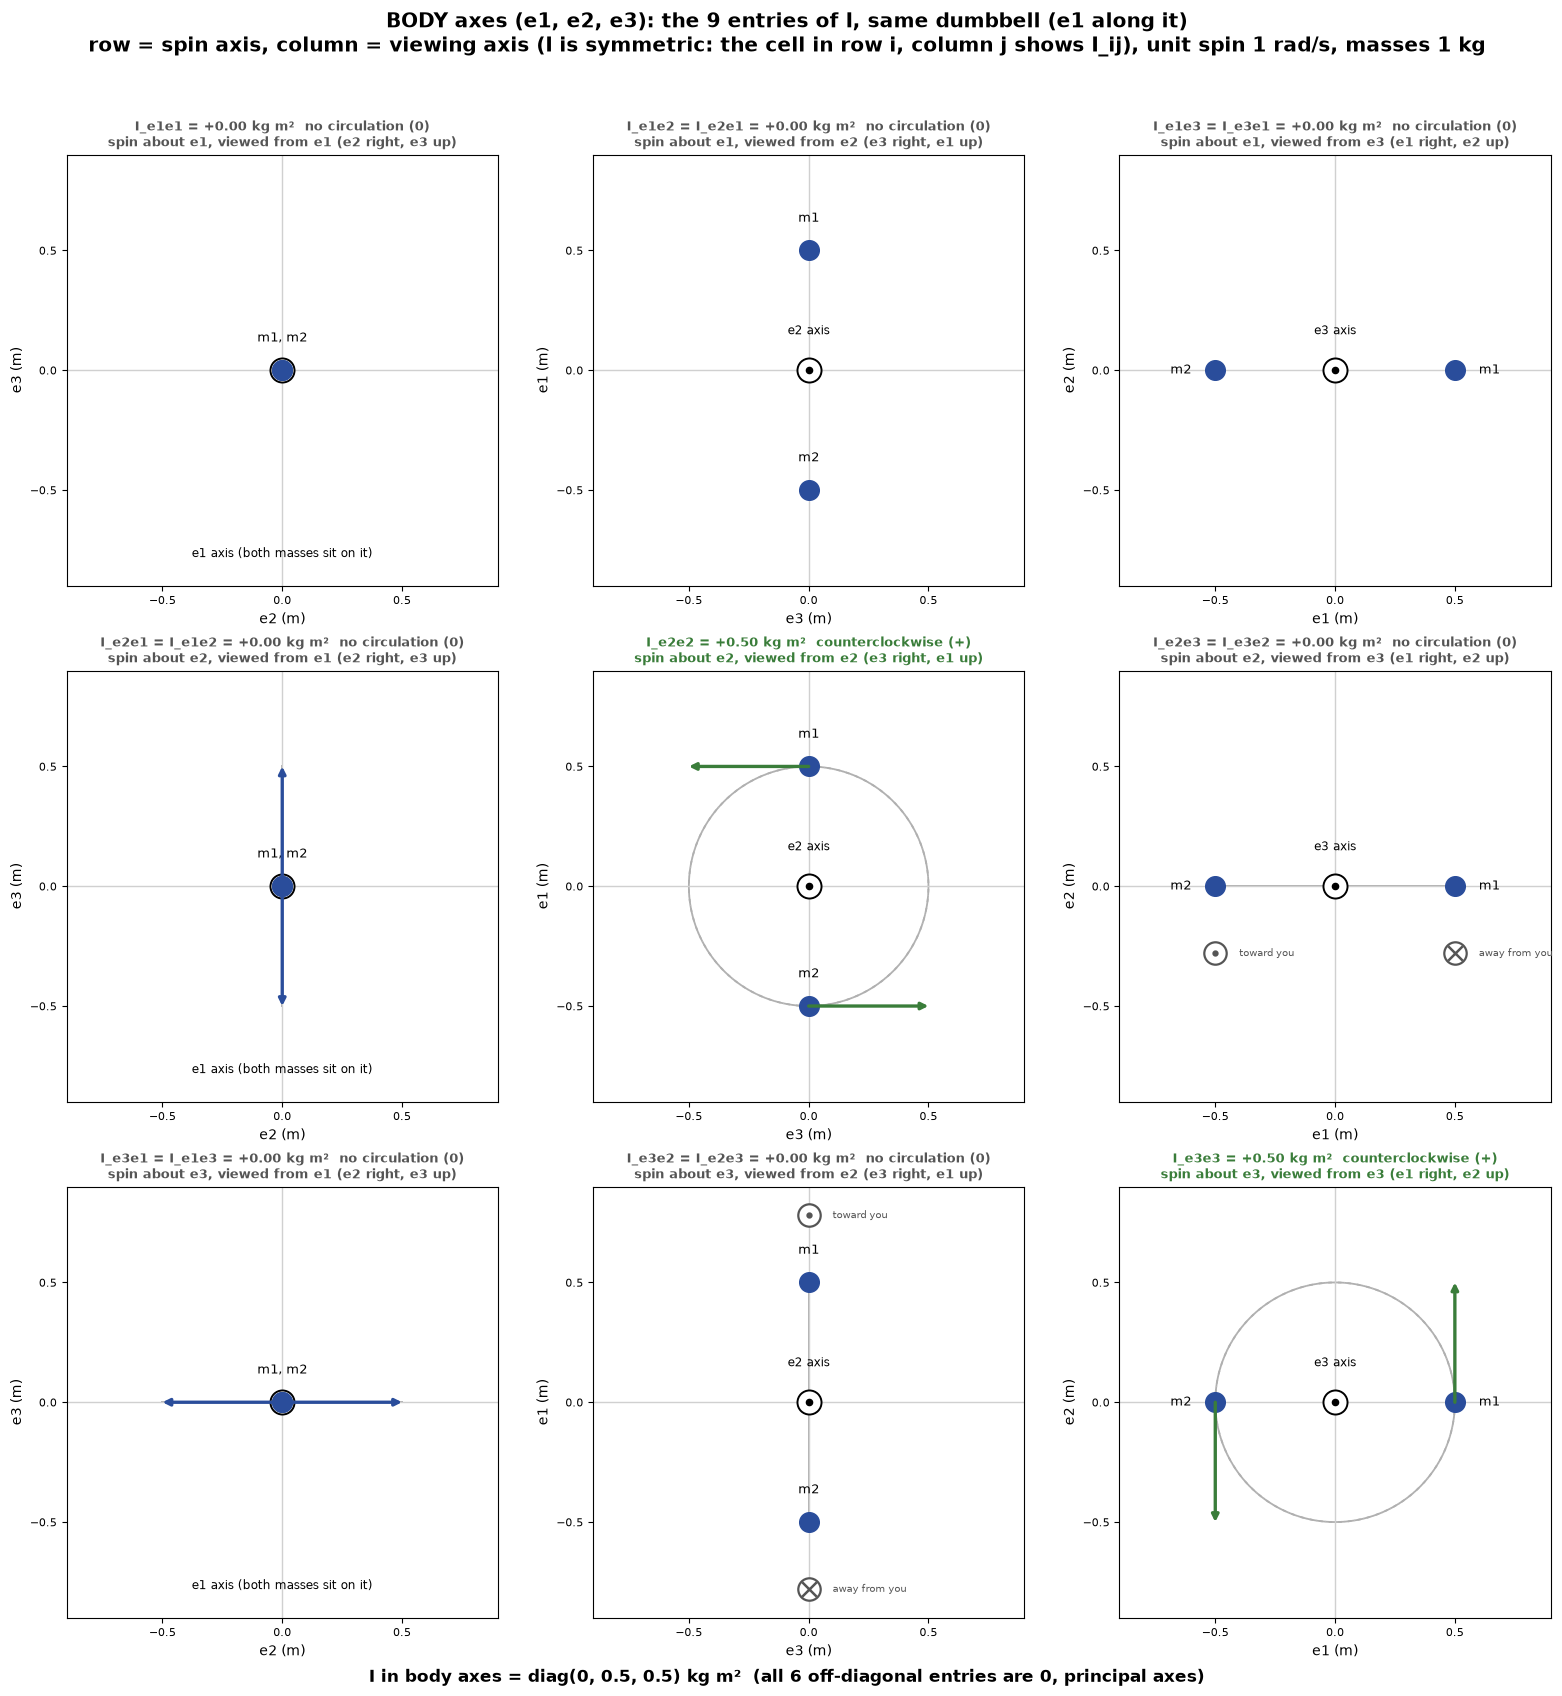

In [4]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: the dumbbell in two sets of axes
#   What we have: two 1 kg masses
#     lab axes (x, y, z):  m1 = (0.354, 0.354, 0) m,  m2 = (-0.354, -0.354, 0) m   (+-0.5 m, tilted 45 degrees in the xy plane)
#     body axes (e1, e2, e3): m1 = (0.5, 0, 0) m, m2 = (-0.5, 0, 0) m  (e1 along the dumbbell)
#   What we want: all 9 entries I_ba of the inertia matrix, each as a picture
#   Why: I_ba = circulation about the viewing axis b when the body spins about axis a at 1 rad/s
#        I_ba = sum m (r x v)_b with v = omega x r,  omega = unit vector along a
#   rows = spin axis, columns = viewing axis  (XX XY XZ / YX YY YZ / ZX ZY ZZ), same layout as the matrix I
#   (I is symmetric, so the cell in row i, column j shows I_ij = I_ji)
# ---------------------------------------------------------------
HALF = 0.5
Q = 0.5 * np.sin(np.deg2rad(45.0))  # 0.354 m
LIM = 0.9
MASS = np.array([1.0, 1.0])  # kg
FRAMES = [
    dict(tag="lab", axes=["x", "y", "z"], pos=np.array([[Q, Q, 0.0], [-Q, -Q, 0.0]]),
         title="LAB axes (x, y, z): the 9 entries of I, dumbbell (1 kg masses at ±0.5 m, tilted 45° in the xy plane)",
         I_expected=np.array([[0.25, -0.25, 0], [-0.25, 0.25, 0], [0, 0, 0.5]], dtype=float),
         foot="I in lab axes = [ 0.25 -0.25 0 ; -0.25 0.25 0 ; 0 0 0.5 ] kg m²  (I_xy = I_yx = -0.25 are not 0)"),
    dict(tag="body", axes=["e1", "e2", "e3"], pos=np.array([[HALF, 0.0, 0.0], [-HALF, 0.0, 0.0]]),
         title="BODY axes (e1, e2, e3): the 9 entries of I, same dumbbell (e1 along it)",
         I_expected=np.diag([0.0, 0.5, 0.5]),
         foot="I in body axes = diag(0, 0.5, 0.5) kg m²  (all 6 off-diagonal entries are 0, principal axes)"),
]
HV = {0: (1, 2), 1: (2, 0), 2: (0, 1)}  # viewing axis -> (horizontal, vertical), cyclic: counterclockwise = positive
GRAY, BLUE, RED, GREEN, DARK = "#888888", "#2a4d9b", "#b03a2e", "#3a7d3a", "#555555"
ARROW = 1.0  # picture metres per (m/s)


def spin_axis_rot(a, f):
    c, s = np.cos(f), np.sin(f)
    if a == 0:
        return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])
    if a == 1:
        return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


# ---------------------------------------------------------------
# STEP 2: one picture = unit spin about axis a, viewed from axis b
#   What we have: positions r, velocities v = e_a x r
#   What we want: the in-plane arrows, the motion along the line of sight, the dashed true path, and I_ba
#   Why: net counterclockwise circulation about b -> I_ba > 0, clockwise -> I_ba < 0, none -> 0
# ---------------------------------------------------------------
def panel(ax, fr, b, a, I_ba):
    pos, names = fr["pos"], fr["axes"]
    h, v_ = HV[b]
    w = np.zeros(3)
    w[a] = 1.0
    vel = np.cross(w, pos)
    ax.set_xlim(-LIM, LIM)
    ax.set_ylim(-LIM, LIM)
    ax.set_aspect("equal")
    ax.axhline(0, color="#d0d0d0", lw=1)
    ax.axvline(0, color="#d0d0d0", lw=1)
    ax.set_xticks([-0.5, 0, 0.5])
    ax.set_yticks([-0.5, 0, 0.5])
    ax.tick_params(labelsize=8)
    ax.set_xlabel(f"{names[h]} (m)", fontsize=10)
    ax.set_ylabel(f"{names[v_]} (m)", fontsize=10)
    color = GREEN if I_ba > 1e-9 else (RED if I_ba < -1e-9 else DARK)
    verdict = ("counterclockwise (+)" if I_ba > 1e-9 else "clockwise (-)") if abs(I_ba) > 1e-9 else "no circulation (0)"
    entry = f"I_{names[a]}{names[a]}" if a == b else f"I_{names[a]}{names[b]} = I_{names[b]}{names[a]}"
    ax.set_title(f"{entry} = {I_ba:+.2f} kg m²  {verdict}\nspin about {names[a]}, viewed from {names[b]}"
                 f" ({names[h]} right, {names[v_]} up)", fontsize=9.5, color=color, fontweight="bold")
    ax.scatter([0], [0], s=300, facecolors="white", edgecolors="black", linewidths=1.4, zorder=3)
    ax.scatter([0], [0], s=20, color="black", zorder=4)
    same = np.allclose(pos[0, [h, v_]], pos[1, [h, v_]])
    if same:
        ax.text(0, -0.78, f"{names[b]} axis (both masses sit on it)", ha="center", fontsize=8.5)
    else:
        ax.text(0, 0.15, f"{names[b]} axis", ha="center", fontsize=8.5)
    phi = np.linspace(0, 2 * np.pi, 200)
    for k in range(2):
        pts = np.array([spin_axis_rot(a, f) @ pos[k] for f in phi])
        if np.ptp(pts[:, h]) > 1e-9 or np.ptp(pts[:, v_]) > 1e-9:
            ax.plot(pts[:, h], pts[:, v_], color="#b0b0b0", ls="--", lw=1.3, zorder=1)
    for k in range(2):
        ax.scatter(pos[k, h], pos[k, v_], s=200, color=BLUE, zorder=5)
        lab = "m1, m2" if same else f"m{k + 1}"
        if not (same and k == 1):
            if abs(pos[k, h]) > 1e-9:
                sd = 1 if pos[k, h] > 0 else -1
                ax.text(pos[k, h] + sd * 0.1, pos[k, v_], lab, ha="left" if sd > 0 else "right", va="center", fontsize=9)
            else:
                ax.text(pos[k, h], pos[k, v_] + 0.12, lab, ha="center", fontsize=9)
        vin = np.array([vel[k, h], vel[k, v_]])
        if np.linalg.norm(vin) > 1e-9:
            ax.annotate("", xy=(pos[k, h] + ARROW * vin[0], pos[k, v_] + ARROW * vin[1]), xytext=(pos[k, h], pos[k, v_]),
                        arrowprops=dict(arrowstyle="-|>", color=color if abs(I_ba) > 1e-9 else BLUE, lw=2.4,
                                        shrinkA=0, shrinkB=0), zorder=6)
        vout = vel[k, b]
        if abs(vout) > 1e-9:
            sgn = 1.0 if pos[k, v_] > 1e-9 else -1.0
            mx, my = pos[k, h], pos[k, v_] + sgn * 0.28
            ax.scatter(mx, my, s=260, facecolors="white", edgecolors=DARK, linewidths=1.6, zorder=7)
            ax.scatter(mx, my, s=30 if vout > 0 else 110, color=DARK, marker="." if vout > 0 else "x", linewidths=1.8, zorder=8)
            ax.text(mx + 0.1, my, "toward you" if vout > 0 else "away from you", ha="left", va="center", fontsize=7.5, color=DARK)


# ---------------------------------------------------------------
# STEP 3: one 3 x 3 image per set of axes
#   Why: compare the lab picture (nonzero off-diagonals) with the body picture (all zero off-diagonals)
# ---------------------------------------------------------------
for fr in FRAMES:
    pos = fr["pos"]
    I_num = np.zeros((3, 3))
    for b in range(3):
        for a in range(3):
            w = np.zeros(3)
            w[a] = 1.0
            I_num[b, a] = (MASS[:, None] * np.cross(pos, np.cross(w, pos)))[:, b].sum()
    assert np.allclose(I_num, fr["I_expected"]), (fr["tag"], I_num)
    fig, axs = plt.subplots(3, 3, figsize=(16, 17.2))
    for a in range(3):
        for b in range(3):
            panel(axs[a, b], fr, b, a, I_num[b, a])
    fig.suptitle(fr["title"] + "\nrow = spin axis, column = viewing axis (I is symmetric: the cell in row i, column j shows I_ij), unit spin 1 rad/s, masses 1 kg",
                 fontsize=14.5, fontweight="bold")
    fig.text(0.5, 0.008, fr["foot"], ha="center", fontsize=12.5, fontweight="bold")
    plt.tight_layout(rect=(0, 0.02, 1, 0.955), h_pad=2.4, w_pad=1.6)
    out_path = os.path.join(RESULT_DIR, f"nine_entries_example_{fr['tag']}_matrix_layout_{TIMESTAMP}.png")
    plt.savefig(out_path, dpi=115)
    print("saved the figure", fr["tag"])